(sec-4-2)=
# 4.2 The Convolution Sum

A moving average replaces an ECG sample with an average of nearby samples. That sounds straightforward, even though the equation used to describe it can look unfamiliar. The equation is a *convolution sum*: multiply selected samples by weights, then add the results.

I will connect that description to the notation one step at a time. We will calculate a small example by hand before using Python and a real ECG. As we go, keep an eye on the tradeoff: averaging can reduce rapid fluctuations, but it can also smooth the sharp parts of a heartbeat.

The operation we will work toward is:

$$
y[n] = \sum_{k=-\infty}^{\infty} x[k]\,h[n-k]
$$

To read the sum, hold the output index $n$ fixed. The index $k$ then runs through the input samples: multiply each $x[k]$ by its corresponding weight $h[n-k]$, and add the products. For a causal three-sample moving average, this reduces to $y[n]=(x[n]+x[n-1]+x[n-2])/3$. If those samples are $0.3$, $0.6$, and $0.9$ mV, the output is $0.6$ mV. We calculate one output value this way, then move to the next index.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)


def stem(ax, n, x, color=C[0], label=None, ms=5):
    """Draw a clean stem plot of the sequence x[n]."""
    ax.vlines(n, 0, x, color=color, lw=1.4)
    ax.plot(n, x, "o", color=color, ms=ms, label=label)
    ax.axhline(0, color="0.55", lw=0.8)

(sec-4-2-1)=
## 4.2.1 Two Ways to Read the Sum

The convolution sum can be read from the input side or from the output side, and I find that switching between the two readings is the quickest way to understand any convolution problem.

**The input-side reading.** Each input sample $x[k]$ launches a copy of the impulse response, scaled by $x[k]$ and starting at time $k$. The output is the sum of all these copies:

$$
y[n] = \cdots + x[0]\,h[n] + x[1]\,h[n-1] + x[2]\,h[n-2] + \cdots
$$

This is the picture behind the derivation in {ref}`Section 4.1.4 <sec-4-1-4>`, and it is the natural one when thinking about how a single event, such as one heartbeat, spreads through a system.

**The output-side reading.** Substitute $m = n - k$ in the sum. As $k$ runs over all integers so does $m$, and $k = n - m$, so

(eq-4-14)=
\begin{equation*}
y[n] = \sum_{m=-\infty}^{\infty} h[m]\,x[n-m]. \tag{4.14}
\end{equation*}

Now $n$ is fixed and we look backwards from it: the output at time $n$ is a weighted sum of the current input $x[n]$ and earlier inputs $x[n-1], x[n-2], \ldots$, with weights $h[0], h[1], h[2], \ldots$. The impulse response acts as a window of weights that slides along the input. This is the picture behind every FIR filter, and it shows at a glance that convolution is commutative, $x * h = h * x$, a property proved formally in [Section 5.4](index.md).

We use one small example throughout the section:

$$
x[n] = \{1, 2, 3, 1\}, \qquad h[n] = \{3, 2, 1\},
$$

both starting at $n = 0$. The impulse response $h$ is a short decaying kernel, a crude version of the exponential smoother of {ref}`Section 4.1.6 <sec-4-1-6>`, and it is deliberately asymmetric so that flipping it makes a visible difference. The figure shows the input-side reading: four scaled, shifted copies of $h$ and their sum.

In [2]:
x = np.array([1.0, 2.0, 3.0, 1.0])
h = np.array([3.0, 2.0, 1.0])
n_axis = np.arange(-1, 8)

copies = []
for k, x_k in enumerate(x):
    copy = np.zeros(n_axis.size)
    copy[(n_axis >= k) & (n_axis < k + h.size)] = x_k * h      # x[k] h[n - k]
    copies.append(copy)
y_superposition = np.sum(copies, axis=0)
print("y[n] by superposition:", y_superposition[(n_axis >= 0) & (n_axis <= 5)])
print("y[n] by np.convolve  :", np.convolve(x, h))

y[n] by superposition: [ 3.  8. 14. 11.  5.  1.]
y[n] by np.convolve  : [ 3.  8. 14. 11.  5.  1.]


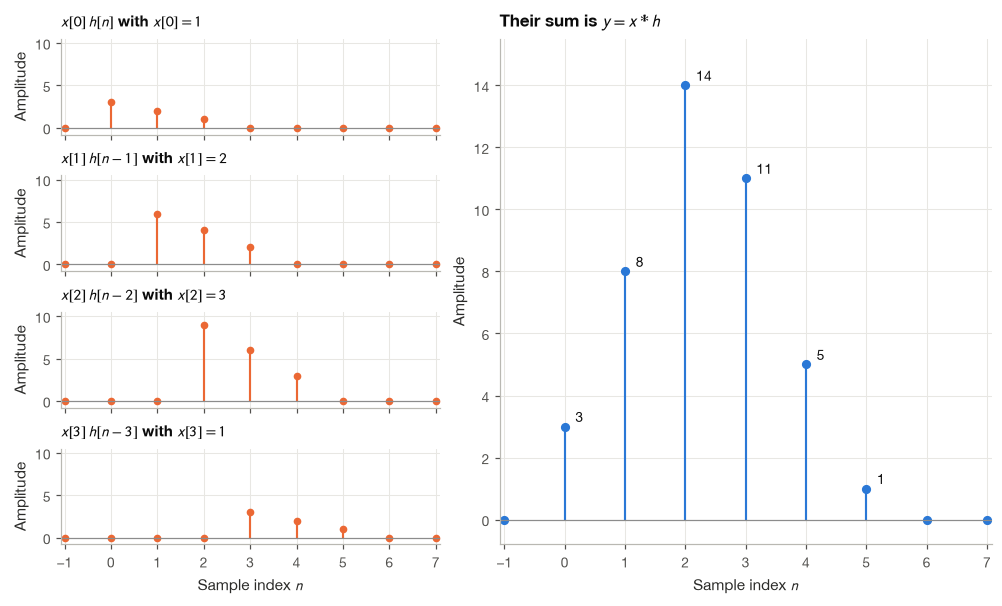

In [3]:
fig = plt.figure(figsize=(9, 5.4))
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.3])
for k, copy in enumerate(copies):
    ax = fig.add_subplot(gs[k, 0])
    stem(ax, n_axis, copy, color=C[1], ms=4)
    shift = "n" if k == 0 else f"n-{k}"
    ax.set(ylim=(-0.8, 10.5), xticks=n_axis, ylabel="Amplitude")
    ax.set_title(f"$x[{k}]\\,h[{shift}]$ with $x[{k}] = {x[k]:g}$", fontsize=10)
    if k == 3:
        ax.set_xlabel("Sample index $n$")
    else:
        ax.tick_params(labelbottom=False)
ax = fig.add_subplot(gs[:, 1])
stem(ax, n_axis, y_superposition, color=C[0])
for n_, y_ in zip(n_axis, y_superposition):
    if y_ != 0:
        ax.annotate(f"{y_:g}", (n_, y_), textcoords="offset points", xytext=(7, 3), fontsize=9)
ax.set(ylim=(-0.8, 15.5), xticks=n_axis, xlabel="Sample index $n$", ylabel="Amplitude",
       title="Their sum is $y = x * h$")
plt.show()

(sec-4-2-2)=
## 4.2.2 The Graphical Method: Flip and Slide

The output-side reading leads to the classic graphical procedure for computing one output value $y[n]$. We treat $k$ as the running variable and $n$ as a fixed parameter.

1. Draw $x[k]$ as a function of $k$.
2. Flip the impulse response about $k = 0$ to obtain $h[-k]$.
3. Slide the flipped copy to the right by $n$ samples to obtain $h[n-k]$. (A positive $n$ moves it to the right because $h[n-k] = h[-(k-n)]$ is $h[-k]$ delayed by $n$.)
4. Multiply $x[k]$ and $h[n-k]$ sample by sample.
5. Add the products. The total is $y[n]$.

Repeating steps 3 to 5 for every $n$ produces the whole output. For our example, the flipped kernel $h[n-k]$ has the value $h[0] = 3$ at $k = n$, $h[1] = 2$ at $k = n-1$ and $h[2] = 1$ at $k = n-2$. The figure shows four positions of the sliding kernel. For $n = -1$ the two sequences do not overlap and $y[-1] = 0$. For $n = 1$ they overlap at $k = 0$ and $k = 1$, giving $y[1] = x[0]h[1] + x[1]h[0] = 1\cdot 2 + 2\cdot 3 = 8$. For $n = 3$ the kernel lies fully inside the input and three products contribute. By $n = 5$ only the last input sample and the last kernel value overlap.

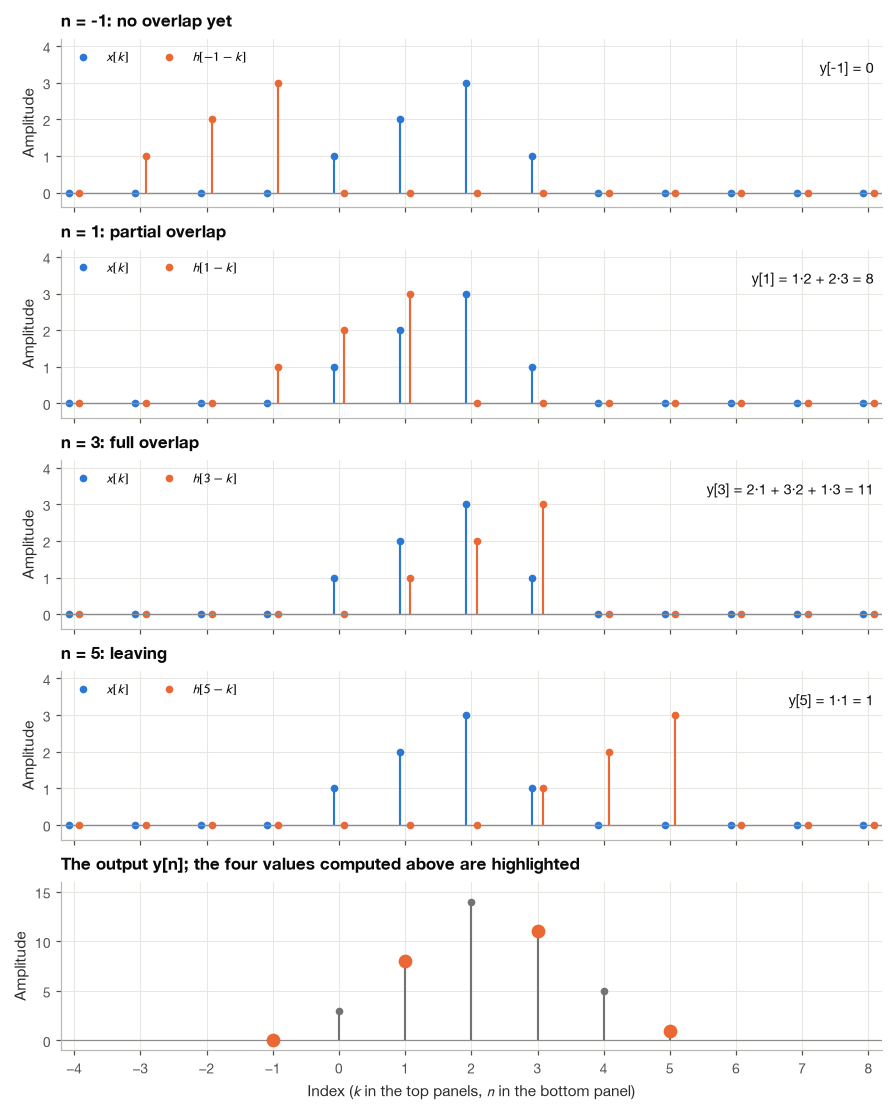

In [4]:
def flip_slide_products(x, h, n):
    """Return the list of (k, x[k], h[n-k]) with a nonzero product, for sequences starting at 0."""
    return [(k, x[k], h[n - k]) for k in range(len(x)) if 0 <= n - k < len(h)]


k_axis = np.arange(-4, 9)
x_k = np.array([x[k] if 0 <= k < len(x) else 0.0 for k in k_axis])
y_full = np.convolve(x, h)
positions = [(-1, "no overlap yet"), (1, "partial overlap"), (3, "full overlap"), (5, "leaving")]

fig, axes = plt.subplots(5, 1, figsize=(8, 10), sharex=True)
for ax, (n_, label) in zip(axes, positions):
    h_flip = np.array([h[n_ - k] if 0 <= n_ - k < len(h) else 0.0 for k in k_axis])
    stem(ax, k_axis - 0.08, x_k, color=C[0], label="$x[k]$", ms=4)
    stem(ax, k_axis + 0.08, h_flip, color=C[1], label=f"$h[{n_}-k]$", ms=4)
    terms = flip_slide_products(x, h, n_)
    total = sum(a * b for _, a, b in terms)
    expr = " + ".join(f"{a:g}·{b:g}" for _, a, b in terms) + f" = {total:g}" if terms else "0"
    ax.text(0.99, 0.88, f"y[{n_}] = {expr}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9.5)
    ax.set(ylim=(-0.4, 4.2), ylabel="Amplitude", title=f"n = {n_}: {label}")
    ax.legend(loc="upper left", ncol=2)
n_out = np.arange(len(y_full))
stem(axes[4], n_out, y_full, color="0.45", ms=4)
for n_, _ in positions:
    if 0 <= n_ < len(y_full):
        axes[4].plot(n_, y_full[n_], "o", color=C[1], ms=8, zorder=3)
axes[4].plot(-1, 0, "o", color=C[1], ms=8, zorder=3)
axes[4].set(ylim=(-1, 16), xlabel="Index ($k$ in the top panels, $n$ in the bottom panel)",
            ylabel="Amplitude", title="The output y[n]; the four values computed above are highlighted")
axes[4].set_xticks(k_axis)
plt.show()

The graphical method is slow for long signals, but it is the method I reach for when I need to know the *shape* of an output without computing it exactly: where it starts, where it ends, and where the overlap is largest. The continuous-time version in [Section 5.3](index.md) relies on the same picture.

(sec-4-2-3)=
## 4.2.3 The Tabular Method

For short sequences there is a faster hand method that organizes the input-side reading in a table. Write $h$ along the top. On row $k$, write $x[k]\,h$, shifted $k$ columns to the right. Then add each column.

| | $n=0$ | $n=1$ | $n=2$ | $n=3$ | $n=4$ | $n=5$ |
|---|---|---|---|---|---|---|
| $x[0]\,h[n] = 1\times\{3,2,1\}$ | 3 | 2 | 1 | | | |
| $x[1]\,h[n-1] = 2\times\{3,2,1\}$ | | 6 | 4 | 2 | | |
| $x[2]\,h[n-2] = 3\times\{3,2,1\}$ | | | 9 | 6 | 3 | |
| $x[3]\,h[n-3] = 1\times\{3,2,1\}$ | | | | 3 | 2 | 1 |
| $y[n]$ (column sums) | **3** | **8** | **14** | **11** | **5** | **1** |

**Example 4.2.1.** Compute $y = x * h$ for $x = \{1, 2, 3, 1\}$ and $h = \{3, 2, 1\}$, both starting at $n = 0$.

Reading down each column of the table:

$$
\begin{aligned}
y[0] &= 3, \\
y[1] &= 2 + 6 = 8, \\
y[2] &= 1 + 4 + 9 = 14, \\
y[3] &= 2 + 6 + 3 = 11, \\
y[4] &= 3 + 2 = 5, \\
y[5] &= 1 ,
\end{aligned}
$$

and $y[n] = 0$ for all other $n$. A useful sanity check is that the output values add up to the product of the input and kernel sums: $3 + 8 + 14 + 11 + 5 + 1 = 42 = 7 \times 6$. We will prove in Section 5.4 that this always holds.

If the table reminds you of long multiplication without carries, that is no accident. Multiply the polynomials whose coefficients are the two sequences, with $w$ as a placeholder variable:

$$
(1 + 2w + 3w^2 + w^3)(3 + 2w + w^2) = 3 + 8w + 14w^2 + 11w^3 + 5w^4 + w^5 .
$$

Collecting the coefficient of $w^n$ requires adding every product $x[k]\,h[m]$ with $k + m = n$, which is exactly the convolution sum. Convolution of sequences *is* polynomial multiplication. This observation becomes the convolution theorem of the z-transform in Section 11.2.

In [5]:
from numpy.polynomial import polynomial as P

print("np.convolve(x, h)      :", np.convolve(x, h))
print("polynomial product     :", P.polymul(x, h))
print(f"sum(y) = {np.convolve(x, h).sum():g},  sum(x) * sum(h) = {x.sum() * h.sum():g}")

np.convolve(x, h)      : [ 3.  8. 14. 11.  5.  1.]
polynomial product     : [ 3.  8. 14. 11.  5.  1.]
sum(y) = 42,  sum(x) * sum(h) = 42


(sec-4-2-4)=
## 4.2.4 Where the Output Lives: Length and Support

Suppose $x[n]$ is nonzero only for $N_1 \le n \le N_1 + N - 1$ (a block of $N$ samples) and $h[n]$ only for $M_1 \le n \le M_1 + M - 1$ (a block of $M$ samples). A term $x[k]\,h[n-k]$ of the convolution sum can be nonzero only if both factors are, that is, if

$$
N_1 \le k \le N_1 + N - 1 \qquad \text{and} \qquad M_1 \le n - k \le M_1 + M - 1 .
$$

Adding the two chains of inequalities (the left ends together and the right ends together) eliminates $k$:

$$
N_1 + M_1 \;\le\; n \;\le\; N_1 + M_1 + N + M - 2 .
$$

So the output starts at the sum of the two starting indices, ends at the sum of the two ending indices, and contains

(eq-4-15)=
\begin{equation*}
L_y = N + M - 1 \tag{4.15}
\end{equation*}

samples. For Example 4.2.1, $N = 4$ and $M = 3$ give $L_y = 6$ samples, from $n = 0$ to $n = 5$, as we found. The rule has a practical consequence that is easy to forget: an output computed with `np.convolve` is longer than the input, and its sample $n$ corresponds to time $(N_1 + M_1 + n)\,T_s$. Losing track of the starting index is the most common source of timing errors when filtering ECGs, because a QRS location shifted by a few samples is enough to spoil an interval measurement.

(sec-4-2-5)=
## 4.2.5 Implementing Convolution from Scratch

Writing convolution ourselves takes a few lines and removes any mystery from the library function. I give three versions, each mirroring one way of thinking about the sum.

The **output-side double loop** computes each $y[n]$ from equation [(4.14)](#eq-4-14), visiting only the indices where both factors are defined. The **input-side loop** follows the tabular method: it loops over the $M$ kernel taps and, for each tap, adds a scaled, shifted copy of the *whole* input to the output. Because the inner work is a NumPy vector operation, this version runs at nearly compiled speed whenever the kernel is short. The **matrix form** writes the whole operation as a matrix-vector product $\mathbf{y} = \mathbf{H}\mathbf{x}$, where column $k$ of $\mathbf{H}$ holds a copy of $h$ shifted down by $k$ rows.

In [6]:
def conv_double_loop(x, h):
    """Convolution by equation (5.14), one output sample at a time."""
    N, M = len(x), len(h)
    y = np.zeros(N + M - 1)
    for n in range(N + M - 1):
        acc = 0.0
        for k in range(max(0, n - N + 1), min(n, M - 1) + 1):
            acc += h[k] * x[n - k]
        y[n] = acc
    return y


def conv_tap_loop(x, h):
    """Convolution as a sum of M scaled, shifted copies of the input (vectorized over n)."""
    N, M = len(x), len(h)
    y = np.zeros(N + M - 1)
    for k in range(M):
        y[k:k + N] += h[k] * x
    return y


def convolution_matrix(h, N):
    """(N + M - 1) x N matrix H such that H @ x equals the full convolution of x with h."""
    M = len(h)
    H = np.zeros((N + M - 1, N))
    for k in range(N):
        H[k:k + M, k] = h
    return H


H = convolution_matrix(h, len(x))
print("Convolution matrix for h = {3, 2, 1} and N = 4:")
print(H)
print("H @ x =", H @ x)

Convolution matrix for h = {3, 2, 1} and N = 4:
[[3. 0. 0. 0.]
 [2. 3. 0. 0.]
 [1. 2. 3. 0.]
 [0. 1. 2. 3.]
 [0. 0. 1. 2.]
 [0. 0. 0. 1.]]
H @ x = [ 3.  8. 14. 11.  5.  1.]


Each column of $\mathbf{H}$ is one row of the table in [Section 4.2.3](#sec-4-2-3) turned on its side, and every diagonal of $\mathbf{H}$ is constant. Matrices with constant diagonals are called **Toeplitz** matrices, and they reappear when we solve the inverse problem of deconvolution in Section 5.4.

We now check the three implementations against `np.convolve` on a random signal of 5000 samples and a 101-tap kernel, and time them.

In [7]:
x_long = rng.normal(size=5000)
h_long = np.hanning(101) / np.hanning(101).sum()

reference = np.convolve(x_long, h_long)
timings = []
for name, func in [("double loop", conv_double_loop), ("tap loop", conv_tap_loop),
                   ("matrix product", lambda a, b: convolution_matrix(b, len(a)) @ a),
                   ("np.convolve", np.convolve)]:
    t0 = time.perf_counter()
    y_test = func(x_long, h_long)
    elapsed = time.perf_counter() - t0
    timings.append({"method": name, "time (ms)": 1000 * elapsed,
                    "max |error|": np.max(np.abs(y_test - reference))})
print(pd.DataFrame(timings).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

        method  time (ms)  max |error|
   double loop       63.4     3.33e-16
      tap loop      0.294     3.33e-16
matrix product       36.5     1.67e-16
   np.convolve     0.0917            0


All four agree to rounding error. The pure-Python double loop is by far the slowest, hundreds of times slower than `np.convolve`, because every multiply-add passes through the Python interpreter. The tap loop comes within a small factor of the library speed. The matrix product wastes most of its effort multiplying zeros and needs memory proportional to $N^2$, so it is a tool for thinking and for small inverse problems rather than for filtering long records.

### How much arithmetic does convolution need?

Each of the $N + M - 1$ outputs needs at most $M$ multiplications, so the direct method costs about

(eq-4-16)=
\begin{equation*}
N \cdot M \ \text{multiply-adds} \tag{4.16}
\end{equation*}

when $N \gg M$. For a 30-minute ECG at 360 Hz ($N \approx 650\,000$) and a 25-tap smoothing kernel this is about 16 million operations, which takes milliseconds. The cost becomes noticeable for long kernels. The AC-coupling filter of {ref}`Section 4.1 <sec-4-1>` had 9167 taps, and applying it to the whole 30-minute record would take some six billion multiply-adds. The fast Fourier transform offers a shortcut: convolving in the frequency domain costs on the order of $(N + M)\log_2(N + M)$ operations, as shown in Section 10.3. SciPy's `signal.fftconvolve` implements it, and `signal.convolve` chooses between the two methods automatically. On five minutes of ECG the difference is already large:

In [8]:
ecg_5min = wfdb.rdrecord("../data/mitdb/100", sampto=300 * 360).p_signal[:, 0]
tau = 1 / (2 * np.pi * 0.05)                                    # AC coupling of Section 5.1
s_step = np.exp(-np.arange(int(8 * tau * 360)) / (tau * 360))
h_ac = np.diff(np.concatenate([[0.0], s_step]))

t0 = time.perf_counter()
y_direct = np.convolve(ecg_5min, h_ac)
t_direct = time.perf_counter() - t0
t0 = time.perf_counter()
y_fft = signal.fftconvolve(ecg_5min, h_ac)
t_fft = time.perf_counter() - t0
print(f"N = {ecg_5min.size}, M = {h_ac.size}")
print(f"direct: {1000 * t_direct:7.1f} ms   FFT: {1000 * t_fft:5.1f} ms   "
      f"max |difference| = {np.max(np.abs(y_direct - y_fft)):.1e} mV")

N = 108000, M = 9167
direct:   183.0 ms   FFT:   3.3 ms   max |difference| = 6.2e-15 mV


The two outputs agree to rounding error, and the FFT method is more than an order of magnitude faster. For short kernels the direct method remains perfectly adequate.

(sec-4-2-6)=
## 4.2.6 Finite Records: Full, Same and Valid Outputs

Real signals have a beginning and an end. Near the edges of a record, the sliding kernel hangs partly outside the data, and the convolution sum has to assume *something* about the missing samples. `np.convolve` and `scipy.signal.convolve` assume they are zero, and offer three ways to trim the result:

| mode | length | which outputs are kept |
|---|---|---|
| `"full"` | $N + M - 1$ | every output with at least one overlapping sample |
| `"same"` | $N$ (for $N \ge M$) | the central $N$ outputs of `"full"`, aligned with the input |
| `"valid"` | $N - M + 1$ | only outputs where the kernel lies entirely inside the data |

For an odd kernel length $M$, the `"same"` output is the full output shifted left by $(M-1)/2$ samples, $y_{\text{same}}[n] = y_{\text{full}}[n + (M-1)/2]$. For a symmetric kernel such as a moving average, this centers the window on each sample, so the smoothed signal lines up with the original in time. The causal `"full"` output, in contrast, is delayed by $(M-1)/2$ samples, the **group delay** of a symmetric FIR filter that we study in Section 13.2.

The zero assumption matters whenever the signal does not hover around zero at its edges. A raw ECG often sits on a DC offset; the first ten seconds of record 100 sit about 0.3 mV below zero. Smoothing it with a 0.5-second moving average, a long kernel chosen here only to make the effect easy to see, gives the result below. The dotted vertical lines mark the first and last recorded samples.

In [9]:
fs = 360
ecg_raw = ecg_5min[:10 * fs]
M_edge = int(0.5 * fs) + 1                                      # 181 taps, 0.5 s
h_edge = np.ones(M_edge) / M_edge

outputs = {mode: np.convolve(ecg_raw, h_edge, mode=mode) for mode in ("full", "same", "valid")}
for mode, y_mode in outputs.items():
    print(f"{mode:>5}: length {y_mode.size}")
padded = np.pad(ecg_raw, (M_edge - 1) // 2, mode="reflect")
y_reflect = np.convolve(padded, h_edge, mode="valid")
print(f"reflect-padded + valid: length {y_reflect.size}")
print(f"first output sample: same = {outputs['same'][0]:.3f} mV,  reflect = {y_reflect[0]:.3f} mV,"
      f"  local mean = {ecg_raw[:fs].mean():.3f} mV")

 full: length 3780
 same: length 3600
valid: length 3420
reflect-padded + valid: length 3600
first output sample: same = -0.095 mV,  reflect = -0.189 mV,  local mean = -0.279 mV


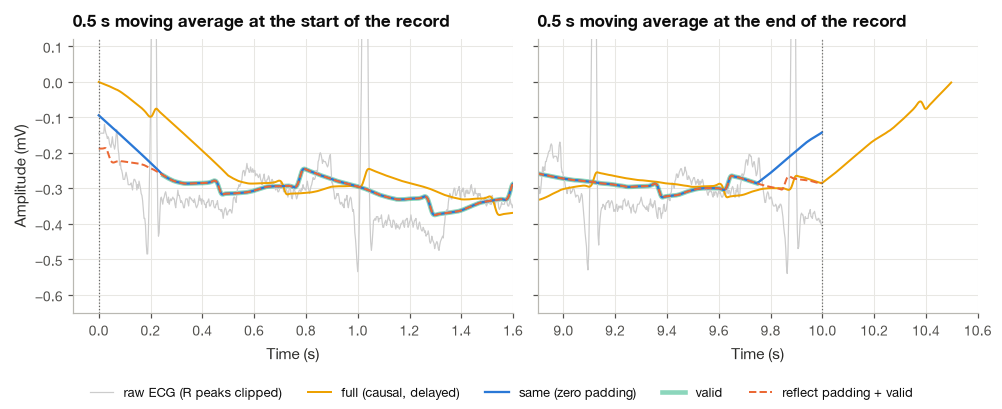

In [10]:
t_raw = np.arange(ecg_raw.size) / fs
half = (M_edge - 1) // 2
t_full = np.arange(outputs["full"].size) / fs
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (lo, hi), side in zip(axes, [(-0.1, 1.6), (8.9, 10.6)], ("start", "end")):
    ax.plot(t_raw, ecg_raw, color="0.8", lw=0.8, label="raw ECG (R peaks clipped)")
    ax.plot(t_full, outputs["full"], color=C[3], lw=1.3, label="full (causal, delayed)")
    ax.plot(t_raw, outputs["same"], color=C[0], lw=1.5, label="same (zero padding)")
    ax.plot(t_raw[half:half + outputs["valid"].size], outputs["valid"], color=C[2], lw=3.0,
            alpha=0.5, label="valid", zorder=1)
    ax.plot(t_raw, y_reflect, color=C[1], lw=1.3, ls="--", label="reflect padding + valid")
    ax.axvline(0 if side == "start" else t_raw[-1], color="0.4", lw=0.8, ls=":")
    ax.set(xlim=(lo, hi), ylim=(-0.65, 0.12), xlabel="Time (s)",
           title=f"0.5 s moving average at the {side} of the record")
axes[0].set_ylabel("Amplitude (mV)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, fontsize=8.5)
plt.show()

The `"same"` output (blue) bends toward zero during the first and last quarter second, because half of the window there is filled with imaginary zeros. The `"full"` output does the same over a full window length and is also delayed. The `"valid"` output avoids the problem by not producing those samples at all, at the price of a shorter result. Padding the record by reflecting it at the edges before a `"valid"` convolution (dashed) is a common compromise: the length is preserved and the edges are filled with plausible values instead of zeros. None of these options creates information that was not recorded; they only decide how to guess.

```{important}
Whenever you filter a record in short blocks, for example 10-second ECG strips for a classifier, edge effects appear in *every* block. Either discard the first and last $(M-1)/2$ samples of each output, or filter the long record once and cut it into blocks afterwards.
```

(sec-4-2-7)=
## 4.2.7 Smoothing a Noisy ECG, Step by Step

We now use convolution for its most common job in ECG work: suppressing muscle noise. I take a clean stretch of record 100 and add real muscle artifact from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984,goldberger2000`, so that we know exactly what the clean signal was and can measure what the filter does to it. I want this example to show the moving average honestly, including where it falls short.

### Step 1: Load a clean ECG and real muscle noise

In [11]:
start, dur = 60 * fs, 10 * fs
clean = wfdb.rdrecord("../data/mitdb/100", sampfrom=start, sampto=start + dur).p_signal[:, 0]
clean = clean - np.median(clean)                                  # remove the DC offset
ma_noise = wfdb.rdrecord("../data/nstdb/ma", sampfrom=start, sampto=start + dur).p_signal[:, 0]
r_ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=start, sampto=start + dur)
r_peaks = r_ann.sample[np.isin(r_ann.symbol, ["N", "A", "V"])] - start
t_ecg = np.arange(dur) / fs
f_w, p_w = signal.welch(ma_noise, fs, nperseg=1024)
below_1hz = p_w[f_w < 1].sum() / p_w.sum()
print(f"{len(r_peaks)} beats in 10 s, mean R amplitude {clean[r_peaks].mean():.2f} mV")
print(f"Fraction of the 'ma' noise power below 1 Hz: {100 * below_1hz:.0f} %")

13 beats in 10 s, mean R amplitude 1.22 mV
Fraction of the 'ma' noise power below 1 Hz: 54 %


The noise record needs one preparatory step. It was recorded from physically active volunteers, with electrodes placed on the limbs where the ECG is not visible, so besides muscle activity it contains slow drift from electrode movement, and more than half of its power lies below 1 Hz. No smoothing filter can remove drift, because drift is itself smooth; that is a job for a high-pass filter. To isolate the muscle component, we subtract from the noise its own 200 ms moving average. The result keeps the fast fluctuations and discards the slow ones, so it is a simple high-pass filter built from a convolution, a construction we analyze in [Section 5.4](index.md). We then scale the muscle noise to 0.1 mV RMS, typical of a tense or shivering patient.

In [12]:
M_hp = int(0.2 * fs) + 1                                          # 73 taps, 200 ms
muscle = ma_noise - np.convolve(ma_noise, np.ones(M_hp) / M_hp, mode="same")
muscle = 0.1 * muscle / muscle.std()                              # 0.1 mV RMS
noisy = clean + muscle
print(f"Muscle noise RMS: {muscle.std():.3f} mV")

Muscle noise RMS: 0.100 mV


### Step 2: Choose the kernel

A moving average of $M$ samples has $h[n] = 1/M$ for $0 \le n \le M-1$. To see how much noise it removes, suppose for a moment that the noise $w[n]$ is white, with independent samples of variance $\sigma^2$. The filtered noise $\sum_k h[k]\,w[n-k]$ is a weighted sum of independent variables, so its variance is the sum of the squared weights times $\sigma^2$:

(eq-4-17)=
\begin{equation*}
\sigma_y^2 = \sigma^2 \sum_{k} h[k]^2 = \sigma^2 \cdot M \cdot \frac{1}{M^2} = \frac{\sigma^2}{M}. \tag{4.17}
\end{equation*}

The noise RMS should therefore fall as $1/\sqrt{M}$. The price is that the window also averages the QRS complex. In record 100 the R wave rises and falls within about 40 ms, so any window approaching that width will flatten it. We try four lengths, from 14 ms to 69 ms.

In [13]:
kernels = {M: np.ones(M) / M for M in (5, 9, 15, 25)}
for M, h_M in kernels.items():
    print(f"M = {M:2d}  ({1000 * M / fs:4.1f} ms)   sum(h) = {h_M.sum():.1f}   sum(h^2) = 1/M = {np.sum(h_M ** 2):.3f}")

M =  5  (13.9 ms)   sum(h) = 1.0   sum(h^2) = 1/M = 0.200
M =  9  (25.0 ms)   sum(h) = 1.0   sum(h^2) = 1/M = 0.111
M = 15  (41.7 ms)   sum(h) = 1.0   sum(h^2) = 1/M = 0.067
M = 25  (69.4 ms)   sum(h) = 1.0   sum(h^2) = 1/M = 0.040


### Step 3: Filter, using linearity to separate signal and noise

Because the filter is linear, filtering the noisy ECG gives the same result as filtering the clean ECG and the noise separately and adding the two outputs. That lets us measure the damage to the ECG and the reduction of the noise independently. We use `mode="same"` so that the smoothed trace stays aligned with the original.

In [14]:
smoothed, smoothed_clean, smoothed_noise = {}, {}, {}
for M, h_M in kernels.items():
    smoothed[M] = np.convolve(noisy, h_M, mode="same")
    smoothed_clean[M] = np.convolve(clean, h_M, mode="same")
    smoothed_noise[M] = np.convolve(muscle, h_M, mode="same")
    assert np.allclose(smoothed[M], smoothed_clean[M] + smoothed_noise[M])   # linearity
print("Filtering signal and noise separately reproduces the filtered sum for every M.")

Filtering signal and noise separately reproduces the filtered sum for every M.


### Step 4: Look at the result

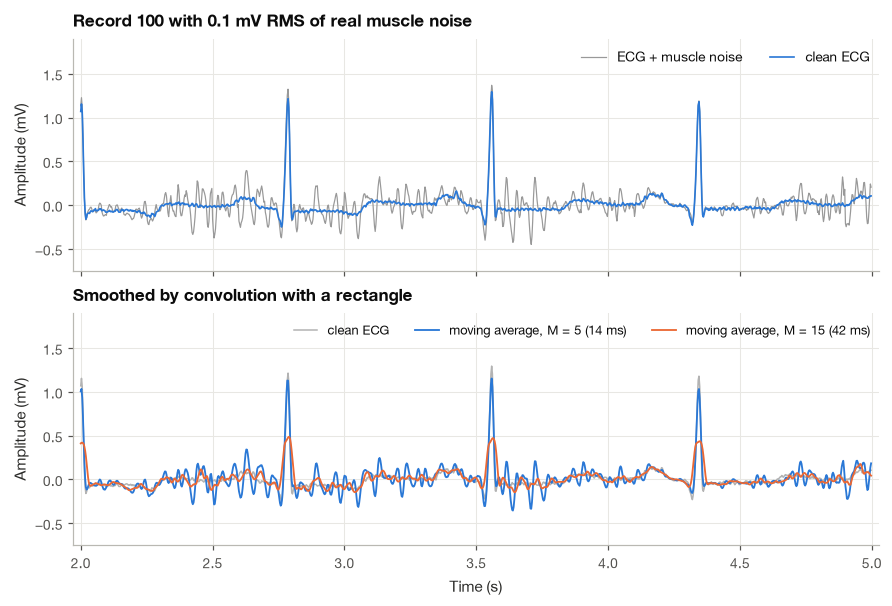

In [15]:
win = (t_ecg >= 2.0) & (t_ecg < 5.0)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
axes[0].plot(t_ecg[win], noisy[win], color="0.6", lw=0.8, label="ECG + muscle noise")
axes[0].plot(t_ecg[win], clean[win], color=C[0], lw=1.1, label="clean ECG")
axes[0].set(ylabel="Amplitude (mV)", title="Record 100 with 0.1 mV RMS of real muscle noise")
axes[0].legend(loc="upper right", ncol=2)
axes[1].plot(t_ecg[win], clean[win], color="0.7", lw=1.0, label="clean ECG")
axes[1].plot(t_ecg[win], smoothed[5][win], color=C[0], lw=1.2, label="moving average, M = 5 (14 ms)")
axes[1].plot(t_ecg[win], smoothed[15][win], color=C[1], lw=1.2, label="moving average, M = 15 (42 ms)")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Smoothed by convolution with a rectangle")
axes[1].legend(loc="upper right", ncol=3, fontsize=8.5)
for ax in axes:
    ax.set_ylim(-0.75, 1.9)
plt.show()

The 42 ms window gives a clean baseline, but the R waves have lost more than half their height. The 14 ms window keeps the QRS shape reasonably well and leaves visible noise behind.

### Step 5: Quantify the trade-off

We measure the RMS of the filtered noise and the fraction of the R-wave amplitude that survives, averaged over the 13 beats.

In [16]:
rows = []
for M in kernels:
    r_kept = np.mean([smoothed_clean[M][r - 5:r + 6].max() / clean[r - 5:r + 6].max() for r in r_peaks])
    rows.append({"M": M, "window (ms)": 1000 * M / fs,
                 "noise RMS (mV)": smoothed_noise[M].std(),
                 "white-noise prediction (mV)": muscle.std() / np.sqrt(M),
                 "R amplitude kept (%)": 100 * r_kept})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 M  window (ms)  noise RMS (mV)  white-noise prediction (mV)  R amplitude kept (%)
 5       13.889           0.076                        0.045                87.761
 9       25.000           0.048                        0.033                65.850
15       41.667           0.030                        0.026                39.103
25       69.444           0.018                        0.020                21.417


Three lessons come out of this table. First, for short windows the noise falls more slowly than the white-noise prediction [(4.17)](#eq-4-17). Muscle noise is not white: much of its power sits between roughly 15 and 40 Hz, so neighboring samples at 360 Hz are strongly correlated, and averaging a few correlated values gains less than averaging independent ones. Second, for longer windows the measured noise catches up with the prediction, and at $M = 25$ it even falls below it. A long window spans whole cycles of the dominant oscillations, and averaging over a full cycle cancels an oscillation completely; a 15-sample window, for example, removes a 24 Hz component exactly ($360/15 = 24$). The moving average has *nulls* at multiples of $f_s/M$, a fact we will read off its zeros in Section 11.3. Third, and most important, the R wave pays for every bit of noise reduction, because the QRS complex and muscle noise occupy the same frequency range. In time-domain terms, any window long enough to average the noise is long enough to average the R wave.

For this record I would accept at most $M = 5$. The moving average is a blunt instrument for ECG denoising, and Section 18.3 shows how filters designed in the frequency domain do better. Convolution is still the operation that applies them; only the kernel changes.

(sec-4-2-8)=
## 4.2.8 Convolution and the Electromyogram

The same arithmetic appears in two different roles in EMG work, which makes the EMG a good second example. In the first role, convolution is a *processing* step that turns a raw EMG into an envelope of muscle activity. In the second, it is a *model* of how the EMG is generated.

### Smoothing a rectified EMG into an envelope

The raw EMG oscillates around zero, so averaging it directly gives nearly nothing. Clinicians and gait laboratories instead rectify the signal (take its absolute value) and then smooth it, which produces an envelope that follows the strength of contraction. We apply this to the needle EMG of a healthy tibialis anterior from the PhysioNet EMG examples {cite:p}`goldberger2000`, sampled at 4 kHz, with moving averages of 50 ms and 200 ms.

In [17]:
emg_rec = wfdb.rdrecord("../data/emgdb/emg_healthy")
fs_emg = emg_rec.fs
emg = emg_rec.p_signal[:, 0]
rectified = np.abs(emg - emg.mean())
envelopes = {}
for width_ms in (50, 200):
    M = int(width_ms * fs_emg / 1000)
    envelopes[width_ms] = np.convolve(rectified, np.ones(M) / M, mode="same")
    print(f"{width_ms:3d} ms window: M = {M:4d} taps, cost N*M = {emg.size * M / 1e6:5.1f} million multiply-adds")

 50 ms window: M =  200 taps, cost N*M =  10.2 million multiply-adds
200 ms window: M =  800 taps, cost N*M =  40.7 million multiply-adds


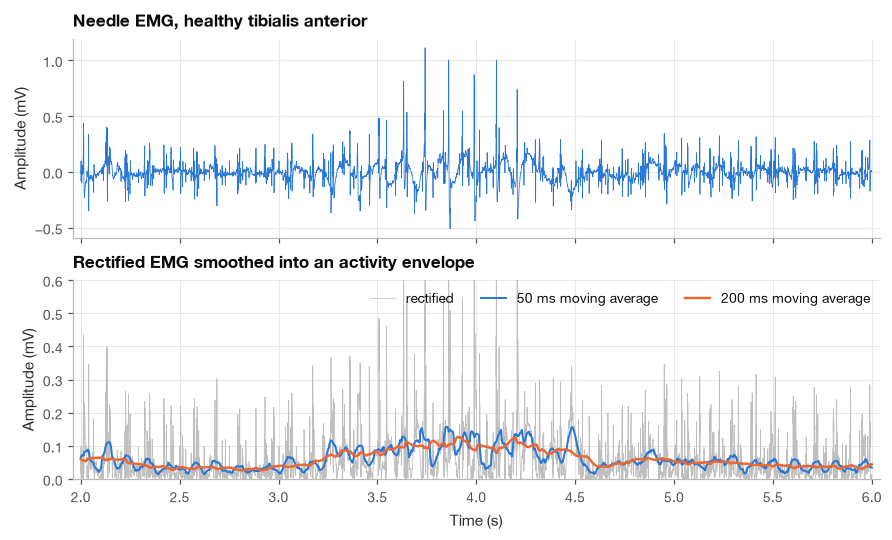

In [18]:
t_emg = np.arange(emg.size) / fs_emg
seg = (t_emg >= 2.0) & (t_emg < 6.0)
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
axes[0].plot(t_emg[seg], emg[seg], color=C[0], lw=0.5)
axes[0].set(ylabel="Amplitude (mV)", title="Needle EMG, healthy tibialis anterior")
axes[1].plot(t_emg[seg], rectified[seg], color="0.75", lw=0.5, label="rectified")
axes[1].plot(t_emg[seg], envelopes[50][seg], color=C[0], lw=1.3, label="50 ms moving average")
axes[1].plot(t_emg[seg], envelopes[200][seg], color=C[1], lw=1.6, label="200 ms moving average")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(0, 0.6),
            title="Rectified EMG smoothed into an activity envelope")
axes[1].legend(loc="upper right", ncol=3)
plt.show()

The 50 ms envelope follows individual bursts of motor unit activity; the 200 ms envelope follows the overall effort. Choosing the window is again a trade-off between noise and temporal detail, and Section 21.2 discusses it for onset detection.

### The EMG as a spike train convolved with a motor unit shape

A motor unit is a single motor neuron together with the muscle fibers it innervates. Each time the neuron fires, all of its fibers discharge almost together, and a nearby electrode records a stereotyped waveform, the **motor unit action potential** (MUAP), lasting roughly 5 to 15 ms. If we represent the firing times $t_1, t_2, \ldots$ as a train of impulses $d[n] = \sum_i \delta[n - n_i]$, the signal of one motor unit is

$$
e[n] = \sum_i \text{MUAP}[n - n_i] = (d * \text{MUAP})[n],
$$

a convolution in which the MUAP plays the role of the impulse response. The EMG is the sum of such convolutions over all active motor units. The simulation below uses three motor units with plausible parameters: MUAPs modeled as scaled second derivatives of Gaussians (a triphasic shape with a duration of about 10 ms) and amplitudes between 0.2 and 0.5 mV, firing at 9, 12 and 15 Hz with 15 % variability in the interspike intervals, as in a weak voluntary contraction.

In [19]:
def muap(t, amplitude, width):
    """Triphasic MUAP model: negative second derivative of a Gaussian (t and width in s)."""
    u = t / width
    return amplitude * (1 - u ** 2) * np.exp(-0.5 * u ** 2)


def spike_train(rate, duration, fs, cv=0.15):
    """Impulse train with mean firing rate (Hz) and interspike-interval variability cv."""
    isi = rng.normal(1 / rate, cv / rate, size=int(3 * rate * duration))
    times = np.cumsum(np.clip(isi, 0.3 / rate, None))
    d = np.zeros(int(duration * fs))
    d[(times[times < duration] * fs).astype(int)] = 1.0
    return d


duration = 1.0
t_kernel = np.arange(-0.01, 0.01, 1 / fs_emg)
units = [(9, 0.5, 1.2e-3), (12, -0.3, 0.9e-3), (15, 0.2, 1.6e-3)]   # (rate Hz, amplitude mV, width s)
trains, shapes, unit_signals = [], [], []
for rate, amp, width in units:
    d = spike_train(rate, duration, fs_emg)
    shape = muap(t_kernel, amp, width)
    trains.append(d)
    shapes.append(shape)
    unit_signals.append(np.convolve(d, shape, mode="same"))
emg_model = np.sum(unit_signals, axis=0)
for (rate, amp, _), d in zip(units, trains):
    print(f"unit firing at {rate:2d} Hz: {int(d.sum()):2d} discharges in {duration:.0f} s, MUAP peak {amp:+.1f} mV")

unit firing at  9 Hz:  9 discharges in 1 s, MUAP peak +0.5 mV
unit firing at 12 Hz: 12 discharges in 1 s, MUAP peak -0.3 mV
unit firing at 15 Hz: 14 discharges in 1 s, MUAP peak +0.2 mV


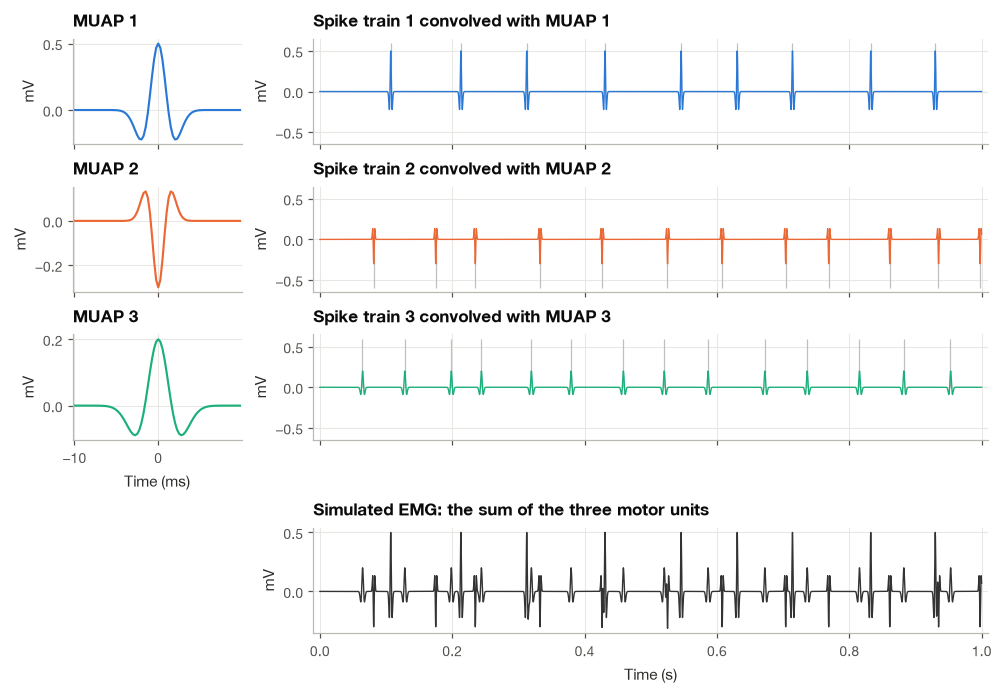

In [20]:
t_model = np.arange(emg_model.size) / fs_emg
fig = plt.figure(figsize=(9, 6.2))
gs = fig.add_gridspec(4, 2, width_ratios=[1, 4])
for i, (d, shape, e) in enumerate(zip(trains, shapes, unit_signals)):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(1000 * t_kernel, shape, color=C[i])
    ax.set(ylabel="mV", title=f"MUAP {i + 1}")
    ax.tick_params(labelbottom=(i == 2))
    if i == 2:
        ax.set_xlabel("Time (ms)")
    ax = fig.add_subplot(gs[i, 1])
    ax.vlines(t_model[d > 0], 0, 0.6 * np.sign(units[i][1]), color="0.75", lw=0.8)
    ax.plot(t_model, e, color=C[i], lw=0.9)
    ax.set(ylabel="mV", ylim=(-0.65, 0.65), title=f"Spike train {i + 1} convolved with MUAP {i + 1}")
    ax.tick_params(labelbottom=False)
ax = fig.add_subplot(gs[3, 1])
ax.plot(t_model, emg_model, color="0.2", lw=0.9)
ax.set(xlabel="Time (s)", ylabel="mV", title="Simulated EMG: the sum of the three motor units")
plt.show()

The gray tick marks are the impulses; each one is replaced by a copy of its unit's MUAP. With three units the individual potentials are still recognizable, which is what a neurologist looks for in a needle examination at weak effort. As more units are recruited and fire faster, the copies overlap and add into the dense interference pattern seen in the real recording above. Section 21.1 builds this model in full and uses it to explain the EMG spectrum.

## Summary

The convolution sum $y[n] = \sum_k x[k]\,h[n-k]$ can be read in two ways: from the input side, as a superposition of scaled and shifted impulse responses, or from the output side, as a window of weights $h[0], h[1], \ldots$ sliding over the input. The graphical flip-and-slide method computes one output at a time and reveals the shape of the result; the tabular method computes all outputs at once and shows that convolution is polynomial multiplication. If the input has $N$ samples and the kernel $M$, the output has $N + M - 1$ samples and starts at the sum of the two starting indices. We implemented convolution as a double loop, a loop over kernel taps and a Toeplitz matrix product, matched `np.convolve` to rounding error, and saw that the direct method costs about $NM$ operations, which motivates the FFT-based methods of Section 10.3.

On finite records, the `full`, `same` and `valid` modes differ in how they treat the edges, and zero padding bends the output toward zero wherever the signal has an offset. Smoothing a real ECG with real muscle noise showed the basic trade-off of every smoothing filter: a longer window removes more noise, at first less than the white-noise rule $1/\sqrt{M}$ predicts because the noise is correlated, but it also removes QRS amplitude, because the QRS and muscle noise share the same frequencies. Finally, convolution served both as a processing step (the EMG envelope) and as a generative model (the EMG as spike trains convolved with motor unit potentials). The next section carries the same ideas over to continuous time.

## Exercises

1. Compute $\{2, -1, 1\} * \{1, 1, 1, 1\}$ by hand with both the graphical and the tabular method. Check that the sum of the output equals the product of the input sums, and verify your answer with `np.convolve`.
2. A signal is nonzero for $-3 \le n \le 10$ and a kernel for $2 \le n \le 6$. Without computing anything, state the first and last indices where the convolution can be nonzero and its length. Then confirm with a random example in Python, being careful about how you track the starting index.
3. Show that the variance formula [(4.17)](#eq-4-17) generalizes to $\sigma_y^2 = \sigma^2 \sum_k h[k]^2$ for any FIR kernel. Among all kernels of length $M$ with $\sum_k h[k] = 1$ (so that a constant signal passes unchanged), which one minimizes $\sum_k h[k]^2$? (Hint: write $h[k] = 1/M + e[k]$ with $\sum_k e[k] = 0$.)
4. Write a function `conv_same(x, h)` that uses `conv_tap_loop` and returns the same output as `np.convolve(x, h, mode="same")` for both odd and even kernel lengths. For even $M$, which half-sample shift does NumPy choose?
5. Repeat the smoothing experiment of [Section 4.2.7](#sec-4-2-7) with a triangular kernel (the convolution of two rectangles of length $(M+1)/2$) and with a Hann window of the same length, normalized to unit sum. Compare the noise RMS and the R amplitude kept with those of the rectangle. Which kernel gives the best trade-off?
6. Extend the EMG model of [Section 4.2.8](#sec-4-2-8) to 20 motor units whose amplitudes and firing rates increase with recruitment order. Plot the simulated signal next to 1 s of the real `emg_healthy` record and compare their rectified-and-smoothed envelopes. What features of the real signal does the model miss?

## Further Reading

The graphical and tabular methods are treated with many examples in {cite:t}`lathi2018` (Chapter 3) and {cite:t}`proakis2007` (Chapter 2); {cite:t}`smith1997` (Chapters 6 and 7) describes the input-side and output-side views in plain language and discusses their computational consequences. For the noise stress test recordings used here, see {cite:t}`moody1984`. The motor unit model of the EMG and the meaning of the EMG envelope are developed in {cite:t}`merletti2004` and {cite:t}`deluca1997`.